# Downloading dataset

In [ ]:
# # download dataset
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("samartalwar/fast-food-calorie-shock-food-vs-workout-burn", output_dir='./dataset')

# print("Path to dataset files:", path)


# Importing dataset 

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("./dataset/data1.csv")


# Structural Overview

In [ ]:
print(df.shape)

In [ ]:
print(df.head())

In [ ]:
print(df.tail())

In [ ]:
print(df.describe())

In [ ]:
print(df.describe(exclude="number").T)

In [ ]:
print(df.info(memory_usage="deep"))

In [ ]:
print(df.dtypes.value_counts())

# Checking Null data

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

no missing data and/or duplicated entries.
This is because this dataset is a generated/calculated data. 

# Visualization
## Level 1 (simple)

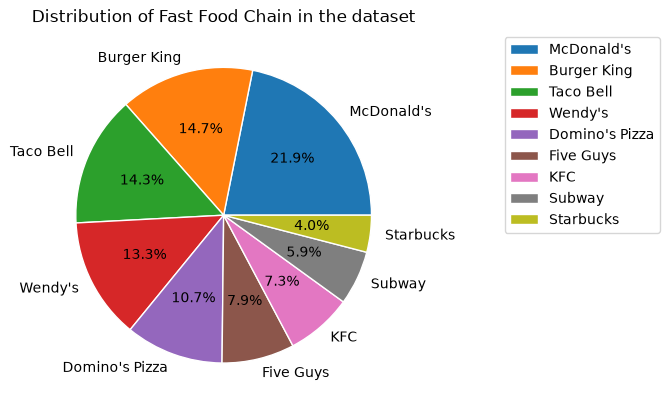

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

ffc = df.fast_food_chain.value_counts()

plt.pie(ffc, labels=list(ffc.index), autopct='%1.1f%%', 
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
    })
plt.title("Distribution of Fast Food Chain in the dataset")
plt.legend(bbox_to_anchor=(1.7, 1), loc='upper right')
plt.show()

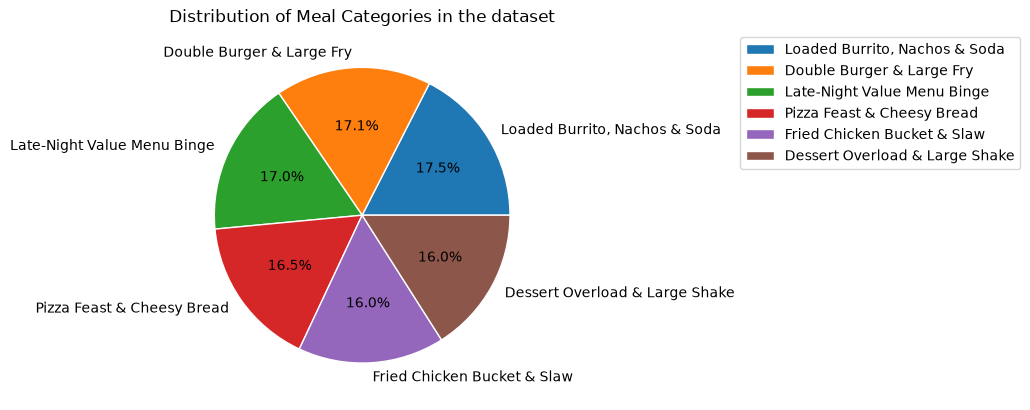

In [ ]:
mc = df.meal_category.value_counts()

plt.pie(mc, labels=list(mc.index), autopct='%1.1f%%', 
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
    })
plt.title("Distribution of Meal Categories in the dataset")
plt.legend(bbox_to_anchor=(2.3, 1), loc='upper right')
plt.show()

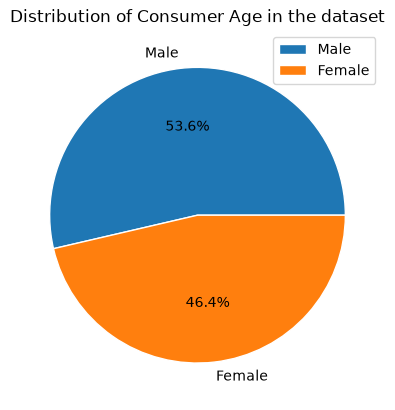

In [70]:
cg = df.consumer_gender.value_counts()

plt.pie(cg, labels=list(cg.index), autopct='%1.1f%%', 
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
    })
plt.title("Distribution of Consumer Age in the dataset")
plt.legend()
plt.show()

In [ ]:
#hole i keep falling
#finding the correct no. of bins

def sturges(col: pd.Series) -> int:
	return round(1+np.log2(col.count()))

def freedman(col: pd.Series) -> int:
    q1 = np.percentile(col, 25)
    q2 = np.percentile(col, 75)
    IQR = q2-q1
    
    n = col.count()
    bin_width = 2 * IQR / (n ** (1/3))

    nobin = int(np.ceil((col.max() - col.min()) / bin_width))
    return nobin

def scott(col: pd.Series) -> int:
    bin_width = 3.5 * np.std(col) / (col.count() ** (1/3))
    scott = int(np.ceil((col.max() - col.min()) / bin_width))
    return scott


# well, i figured bins='auto' also does the same

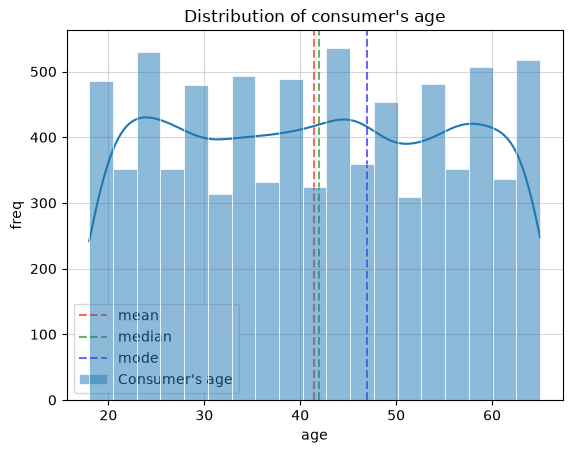

In [135]:
ca = df.consumer_age

sns.histplot(ca, bins='auto', kde=True, edgecolor='white', label="Consumer's age", zorder=10, linewidth=0.5)

plt.axvline(ca.mean(), color="red", ls="--", alpha=0.6, label="mean")
plt.axvline(ca.median(), color="green", ls="--", alpha=0.6, label="median")
plt.axvline(ca.mode()[0], color="blue", ls="--", alpha=0.6, label="mode")

plt.title("Distribution of consumer's age")
plt.xlabel('age')
plt.ylabel('freq')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

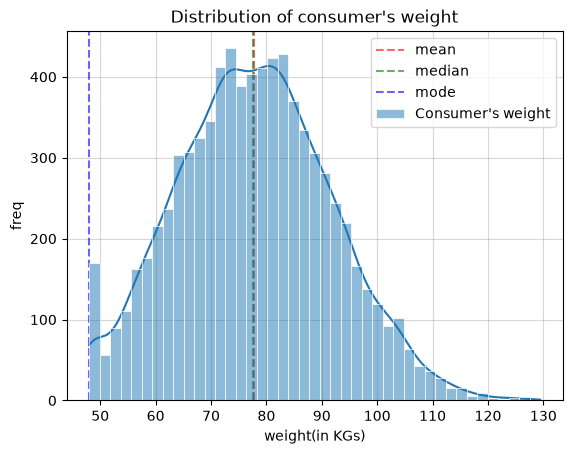

In [132]:
cw = df.consumer_weight_kg

sns.histplot(cw, bins='auto', kde=True, label="Consumer's weight", zorder=10, linewidth=0.5, edgecolor='white')

plt.axvline(cw.mean(), color="red", ls="--", alpha=0.6, label="mean")
plt.axvline(cw.median(), color="green", ls="--", alpha=0.6, label="median")
plt.axvline(cw.mode()[0], color="blue", ls="--", alpha=0.6, label="mode")

plt.title("Distribution of consumer's weight")
plt.xlabel('weight(in KGs)')
plt.ylabel('freq')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

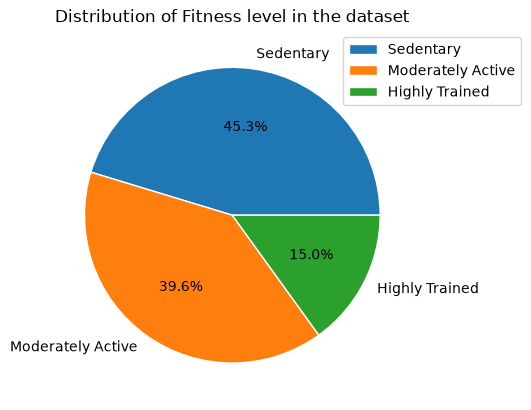

In [124]:
fl = df.fitness_level.value_counts()

plt.pie(fl, labels=list(fl.index), autopct='%1.1f%%', 
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
    })
plt.title("Distribution of Fitness level in the dataset")
plt.legend(bbox_to_anchor=(1.3, 1), loc='upper right')
plt.show()

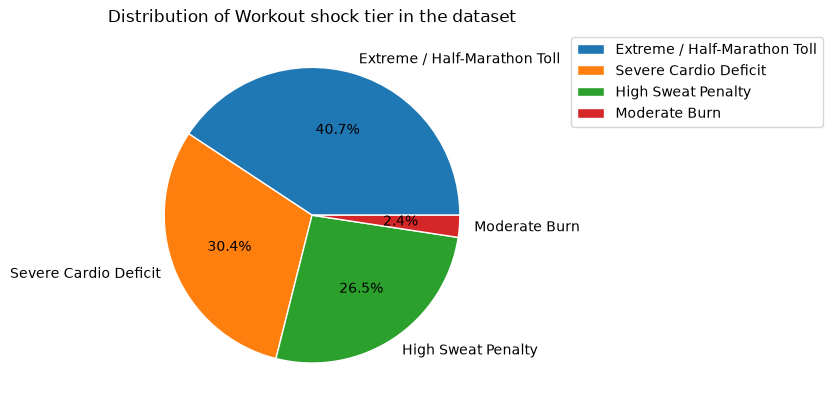

In [116]:
wst = df.workout_shock_tier.value_counts()

plt.pie(wst, labels=list(wst.index), autopct='%1.1f%%', 
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
    })
plt.title("Distribution of Workout shock tier in the dataset")
plt.legend(bbox_to_anchor=(1.9, 1), loc='upper right')
plt.show()

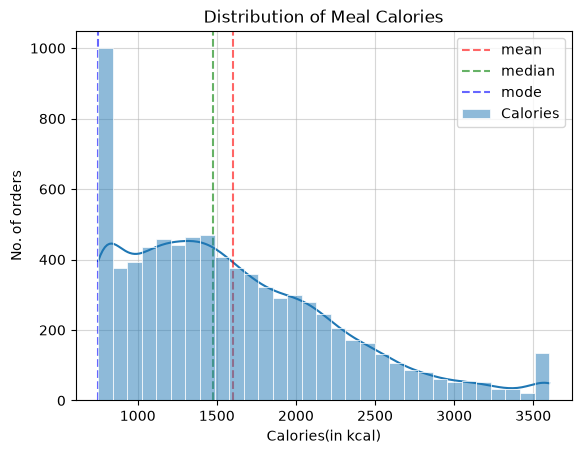

In [131]:
tc = df.total_calories

sns.histplot(tc, bins='auto', kde=True, label="Calories", zorder=10, linewidth=0.5, edgecolor='white')

plt.axvline(tc.mean(), color="red", ls="--", alpha=0.6, label="mean")
plt.axvline(tc.median(), color="green", ls="--", alpha=0.6, label="median")
plt.axvline(tc.mode()[0], color="blue", ls="--", alpha=0.6, label="mode")

plt.title("Distribution of Meal Calories")
plt.xlabel('Calories(in kcal)')
plt.ylabel('No. of orders')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

## Level 2

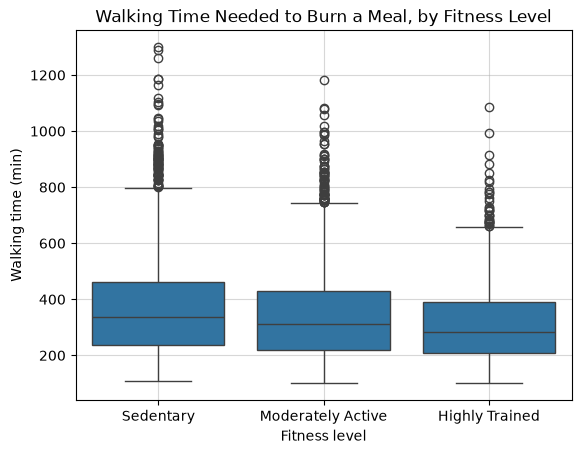

In [141]:
order = ["Sedentary", "Moderately Active", "Highly Trained"]

sns.boxplot(data=df, x="fitness_level", y="walking_burn_time_min", order=order)
plt.title("Walking Time Needed to Burn a Meal, by Fitness Level")
plt.xlabel("Fitness level")
plt.ylabel("Walking time (min)")
plt.grid(alpha=0.5)
plt.show()

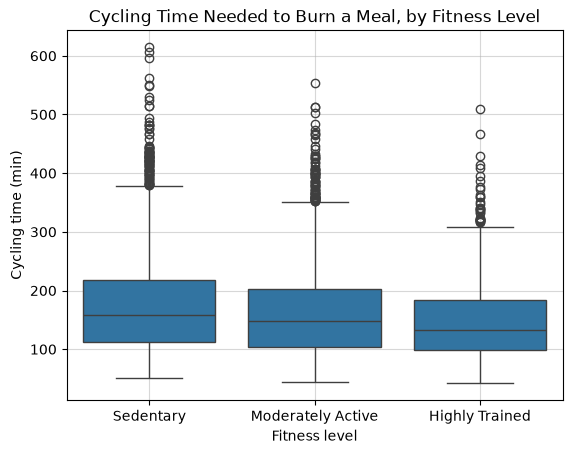

In [142]:
sns.boxplot(data=df, x="fitness_level", y="cycling_burn_time_min", order=order)
plt.title("Cycling Time Needed to Burn a Meal, by Fitness Level")
plt.xlabel("Fitness level")
plt.ylabel("Cycling time (min)")
plt.grid(alpha=0.5)
plt.show()

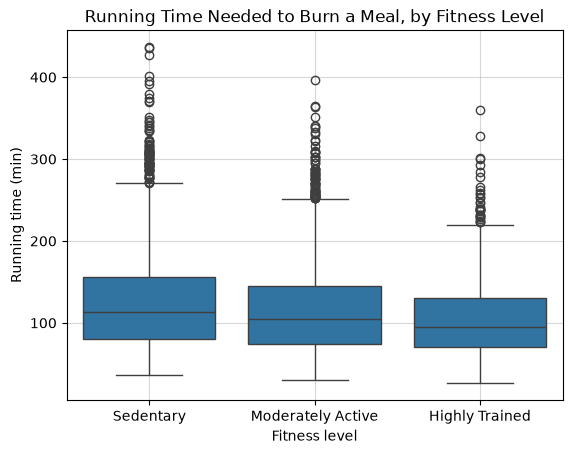

In [ ]:
sns.boxplot(data=df, x="fitness_level", y="running_burn_time_min", order=order)
plt.title("Running Time Needed to Burn a Meal, by Fitness Level")
plt.xlabel("Fitness level")
plt.ylabel("Running time (min)")
plt.grid(alpha=0.5)
plt.show()

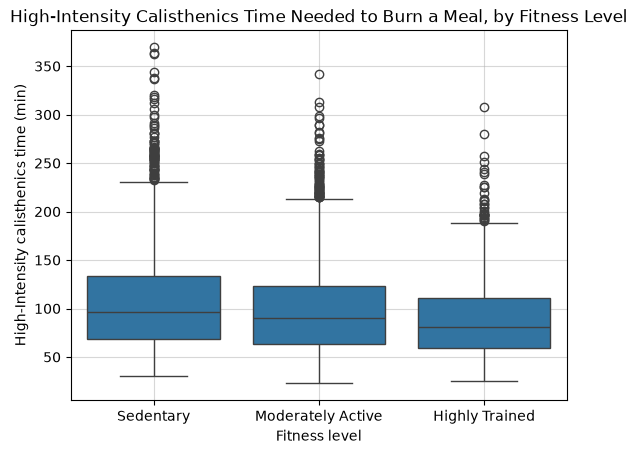

In [143]:
sns.boxplot(data=df, x="fitness_level", y="hiit_burn_time_min", order=order)
plt.title("High-Intensity Calisthenics Time Needed to Burn a Meal, by Fitness Level")
plt.xlabel("Fitness level")
plt.ylabel("High-Intensity calisthenics time (min)")
plt.grid(alpha=0.5)
plt.show()

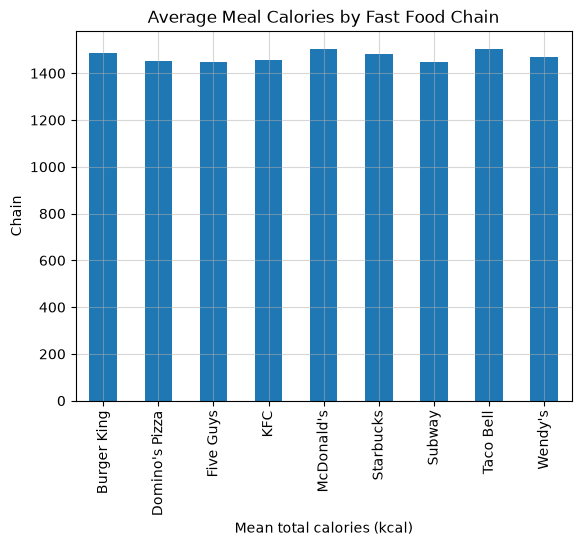

In [150]:
# Chart 3: average calories by chain
chain_avg = df.groupby("fast_food_chain")["total_calories"].mean()
chain_med = df.groupby("fast_food_chain")["total_calories"].median()
# plt.figure(figsize=(8, 5))
# chain_avg.plot(kind="bar")
chain_med.plot(kind="bar")
plt.title("Average Meal Calories by Fast Food Chain")
plt.xlabel("Mean total calories (kcal)")
plt.ylabel("Chain")
plt.grid(alpha=0.5)
plt.show()

compare both mean and median above
compare all nutri from each company
follow grail